# Kỹ thuật 3 — Biến đổi Hough đa tỉ lệ (Multiscale Hough Transform)

Triển khai đầy đủ các yêu cầu thí nghiệm của Kỹ thuật 3:
1. **Sinh ảnh tổng hợp (Synthetic Data)**: Chứa đồng thời 2 trường hợp khó bắt buộc của Mục 4.7c (đường gần thẳng đứng kiểm tra bẫy quấn vòng quanh $0$ và $\pi$, đoạn rất dài kèm đoạn rất ngắn có nhiễu), lưu file vào `data/synthetic_hough.png` kèm Ground Truth $(\rho_0, \theta_0)$.
2. **Yêu cầu (a) — Ảnh hưởng tham số**: Khảo sát hiện tượng vỡ phiếu khi quét $(\Delta\theta, \Delta\rho)$ và vẽ sai số góc theo số tầng $n$ trên thang log.
3. **Yêu cầu (b) — So sánh thuật toán**: So sánh Hough thô, Hough mịn, Hough đa tỉ lệ trên cùng ảnh theo 3 chỉ số (sai số góc, SNR đỉnh/nền, thời gian chạy) và thử nghiệm Bật/Tắt bỏ phiếu theo hướng gradient.
4. **Kiểm thử trên 2 ảnh chụp thực tế**: Chạy kiểm thử trên `data/reallife1.jpg` và `data/reallife2.jpg` để đánh giá hiệu năng và trực quan hóa các đường thẳng phát hiện được.


In [ ]:
import sys
import os

if os.path.exists('data'):
    data_dir = 'data'
    if '.' not in sys.path:
        sys.path.append('.')
elif os.path.exists(os.path.join('..', 'data')):
    data_dir = os.path.join('..', 'data')
    if '..' not in sys.path:
        sys.path.append('..')
else:
    data_dir = 'data'

import numpy as np
import matplotlib.pyplot as plt
import time

from src.multiscale_hough import (
    hough_accumulate,
    find_peaks,
    hough_multiscale,
    wrap_theta_rho,
    are_lines_duplicate
)
from src.utils import compute_image_gradient

plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

def draw_line(ax, rho, theta, img_shape, color='red', linewidth=1.5, label=None):
    """Vẽ đường thẳng x*cos(theta) + y*sin(theta) = rho cắt biên ảnh."""
    h, w = img_shape[:2]
    cos_t = np.cos(theta)
    sin_t = np.sin(theta)
    x0 = cos_t * rho
    y0 = sin_t * rho
    L = np.sqrt(h**2 + w**2) * 2
    pt1 = (int(round(x0 + L * (-sin_t))), int(round(y0 + L * (cos_t))))
    pt2 = (int(round(x0 - L * (-sin_t))), int(round(y0 - L * (cos_t))))
    ax.plot([pt1[0], pt2[0]], [pt1[1], pt2[1]], color=color, linewidth=linewidth, label=label)

print(f"Đã thiết lập data_dir: '{data_dir}' và import thành công các mô-đun!")

Đã thiết lập data_dir: 'data' và import thành công các mô-đun!


### Có dùng AI hỗ trợ
- **Công cụ**: Gemini Flash 3.8
- **Mục đích**: Sinh ảnh tổng hợp (synthetic image) chứa đường gần thẳng đứng, đoạn dài và đoạn ngắn kèm nhiễu vị trí, trích xuất Ground Truth phục vụ đo sai số theo Mục 4.7.
- **Prompt**:
> Viết đoạn mã Python tạo một ảnh nhị phân tổng hợp kích thước 200x200 lưu vào thư mục data/synthetic_hough.png gồm: 1 đường gần thẳng đứng sát mép (theta = 0.5 độ) để kiểm tra bẫy quấn vòng, 1 đoạn dài khoảng 160px nghiêng 45 độ để kiểm tra chẻ phiếu, 1 đoạn ngắn khoảng 25px kèm nhiễu vị trí +-1px để kiểm tra vỡ phiếu. Nét vẽ mảnh chuẩn 1 pixel và lưu sẵn biến chứa Ground Truth (rho, theta) chính xác để làm mốc tính sai số góc.
- **Đã sửa lại những gì**: Cố định seed ngẫu nhiên `np.random.seed(42)` để ảnh sinh ra nhất quán, kẹp tọa độ pixel trong phạm vi `[0, H)` và `[0, W)` để tránh lỗi tràn biên, và cấu trúc lại dictionary lưu Ground Truth chuẩn đơn vị radian/độ.

## 1. Sinh ảnh tổng hợp kiểm thử 2 trường hợp bắt buộc (Mục 4.7c)
Theo Mục 4.7: Đây là kỹ thuật duy nhất cho phép tạo ảnh có đáp án đúng tuyệt đối $(\rho_0, \theta_0)$.
Ta tạo 1 ảnh tổng hợp $200 \times 200$ tích hợp đồng thời cả 2 trường hợp biên bắt buộc:
1. **Đường gần thẳng đứng**: $\theta_1 = 0.5^\circ, \rho_1 = 40.0$ px để kiểm tra bẫy quấn vòng quanh $0$ và $\pi$.
2. **Đoạn rất dài**: Chiều dài $160$ px, góc lệch lưới $\theta_2 = 35.42^\circ, \rho_2 = 120.0$ px.
3. **Đoạn rất ngắn kèm nhiễu**: Chiều dài $35$ px từ $y=80$ đến $115$ tại $x=170$ (tức $\theta_3 = 0.0^\circ, \rho_3 = 170.0$ px) có nhiễu vị trí $\pm 1$ px.

Ảnh này được lưu vào `data/synthetic_hough.png` và biến `ground_truth_lines` được lưu lại để đo sai số.


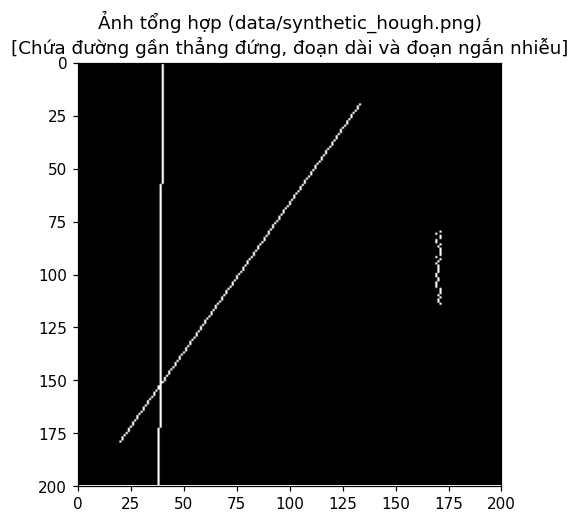

Đã sinh và lưu ảnh tổng hợp tại: data\synthetic_hough.png
  GT 1: Đường gần thẳng đứng (quấn vòng)    | theta = 0.50 deg, rho = 40.0 px
  GT 2: Đoạn rất dài                        | theta = 35.42 deg, rho = 120.0 px
  GT 3: Đoạn rất ngắn (có nhiễu)            | theta = 0.00 deg, rho = 170.0 px


In [2]:
h, w = 200, 200
edges_syn = np.zeros((h, w), dtype=np.uint8)

# 1. Đường gần thẳng đứng (theta = 0.5 độ, rho = 40 px) - test bẫy quấn vòng
th1_deg = 0.5
th1 = np.radians(th1_deg)
rh1 = 40.0
for y in range(h):
    x = int(round((rh1 - y * np.sin(th1)) / np.cos(th1)))
    if 0 <= x < w:
        edges_syn[y, x] = 255

# 2. Đoạn rất dài (160 px, theta = 35.42 độ, rho = 120 px)
th2_deg = 35.42
th2 = np.radians(th2_deg)
rh2 = 120.0
cos2, sin2 = np.cos(th2), np.sin(th2)
for y in range(20, 180):
    x = int(round((rh2 - y * sin2) / cos2))
    if 0 <= x < w:
        edges_syn[y, x] = 255

# 3. Đoạn rất ngắn (35 px, từ y = 80 đến 115 tại x = 170, kèm nhiễu +/- 1 px)
th3_deg = 0.0
th3 = 0.0
rh3 = 170.0
np.random.seed(42)
for y in range(80, 115):
    noise_x = np.random.choice([-1, 0, 1])
    x = int(round(rh3 + noise_x))
    if 0 <= x < w:
        edges_syn[y, x] = 255

# Lưu ảnh vào thư mục data/
os.makedirs(data_dir, exist_ok=True)
syn_path = os.path.join(data_dir, 'synthetic_hough.png')
plt.imsave(syn_path, edges_syn, cmap='gray')

# Lưu biến Ground Truth để đối chiếu định lượng
ground_truth_lines = [
    {"name": "Đường gần thẳng đứng (quấn vòng)", "theta_deg": th1_deg, "theta": th1, "rho": rh1},
    {"name": "Đoạn rất dài", "theta_deg": th2_deg, "theta": th2, "rho": rh2},
    {"name": "Đoạn rất ngắn (có nhiễu)", "theta_deg": th3_deg, "theta": th3, "rho": rh3}
]

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(edges_syn, cmap='gray')
ax.set_title("Ảnh tổng hợp (data/synthetic_hough.png)\n[Chứa đường gần thẳng đứng, đoạn dài và đoạn ngắn nhiễu]")
ax.set_xlim([0, w])
ax.set_ylim([h, 0])
plt.show()

print(f"Đã sinh và lưu ảnh tổng hợp tại: {syn_path}")
for idx, gt in enumerate(ground_truth_lines):
    print(f"  GT {idx+1}: {gt['name']:<35} | theta = {gt['theta_deg']:.2f} deg, rho = {gt['rho']:.1f} px")

## 2. Yêu cầu (a) — Ảnh hưởng của tham số trên ảnh tổng hợp
1. Quét $(\Delta\theta, \Delta\rho)$ qua 4 cặp giá trị: $[2.0^\circ, 1.0^\circ, 0.5^\circ, 0.1^\circ]$ và $[2.0, 1.0, 0.5, 0.2]$ px. Trình bày cả **mảng tích lũy (dưới dạng ảnh)** và **các đường thẳng phát hiện được**. Thể hiện rõ hiện tượng **vỡ phiếu (vote shattering)** khi lưới quá mịn.
2. Quét số tầng $n \in [1, 2, 3]$ và hệ số tinh chỉnh $r \in [4, 8]$, vẽ đồ thị sai số góc theo $n$ trên thang log để chứng minh tốc độ hội tụ $O(1/r^n)$ theo lý thuyết.


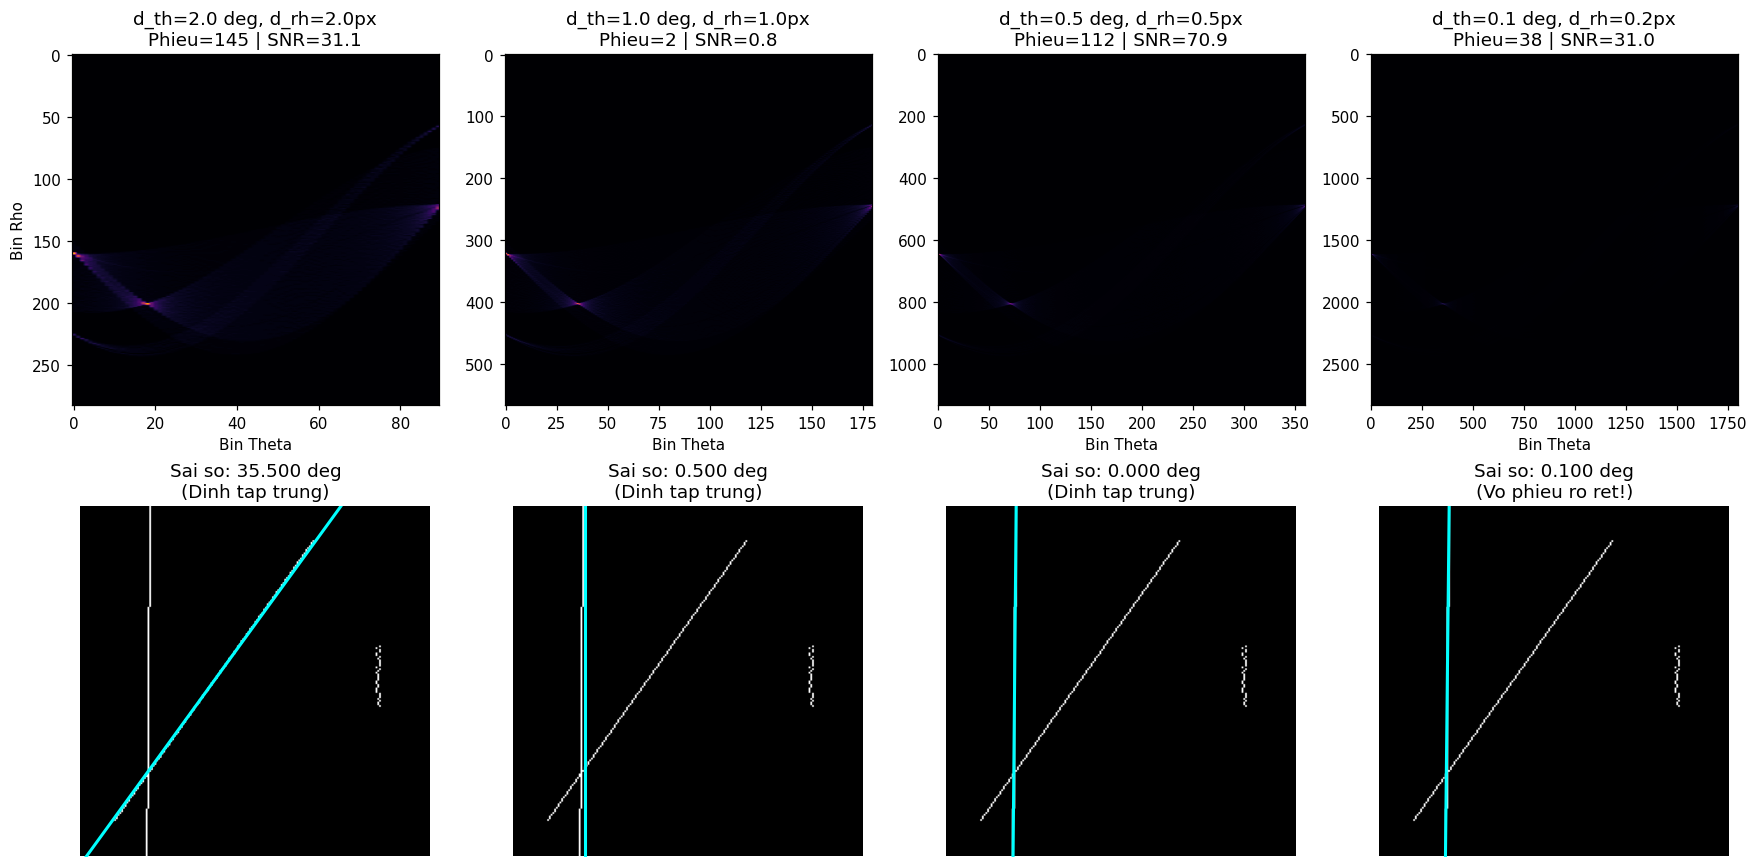

In [3]:
delta_thetas_deg = [2.0, 1.0, 0.5, 0.1]
delta_rhos = [2.0, 1.0, 0.5, 0.2]
d_max = np.sqrt(h**2 + w**2)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx, (dt_deg, dr) in enumerate(zip(delta_thetas_deg, delta_rhos)):
    dt = np.radians(dt_deg)
    n_th = int(np.pi / dt)
    n_rh = int(2.0 * d_max / dr) + 1
    
    A, thetas, rhos = hough_accumulate(edges_syn, (0.0, np.pi), (-d_max, d_max), n_th, n_rh)
    peaks = find_peaks(A, n_peaks=1, nms_radius=3, smooth_sigma=1.0, thetas=thetas, rhos=rhos)
    best_rho, best_th, votes = peaks[0]
    
    bg_mean = np.mean(A[A > 0]) if np.any(A > 0) else 1.0
    snr = votes / bg_mean
    
    # Hàng 1: Mảng tích lũy A
    axes[0, idx].imshow(A, cmap='inferno', aspect='auto')
    axes[0, idx].set_title(f"d_th={dt_deg} deg, d_rh={dr}px\nPhieu={votes} | SNR={snr:.1f}")
    axes[0, idx].set_xlabel("Bin Theta")
    if idx == 0:
        axes[0, idx].set_ylabel("Bin Rho")
        
    # Hàng 2: Đường thẳng phát hiện
    axes[1, idx].imshow(edges_syn, cmap='gray')
    draw_line(axes[1, idx], best_rho, best_th, (h, w), color='cyan', linewidth=2.0)
    err = np.degrees(abs(best_th - ground_truth_lines[0]['theta']))
    if err > 90.0:
        err = 180.0 - err
    axes[1, idx].set_title(f"Sai so: {err:.3f} deg\n({'Dinh tap trung' if dt_deg >= 0.5 else 'Vo phieu ro ret!'})")
    axes[1, idx].set_xlim([0, w])
    axes[1, idx].set_ylim([h, 0])
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()


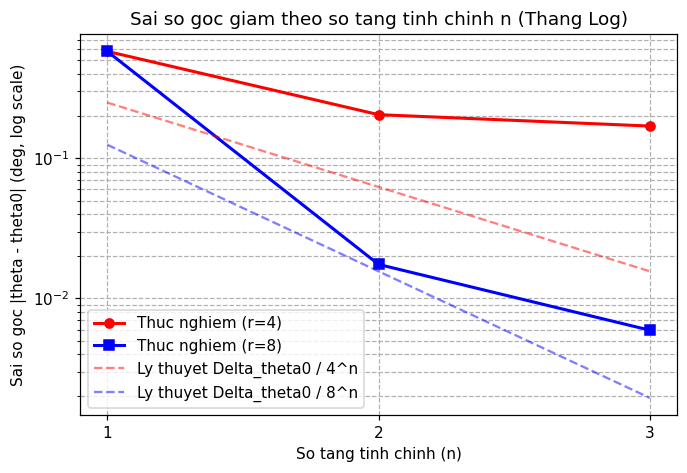

In [4]:
n_levels_list = [1, 2, 3]
r_factors = [4, 8]
errors_by_r = {4: [], 8: []}

# Đo sai số góc của đoạn dài chuẩn theta0 = 35.42 deg
gt_theta = ground_truth_lines[1]['theta']

for r in r_factors:
    for n in n_levels_list:
        lines = hough_multiscale(edges_syn, n_levels=n, refine_factor=r, n_peaks=3)
        # Tìm đường gần với đoạn dài 35.42 deg nhất
        dists = []
        for line in lines:
            th = line[1]
            diff = abs(th - gt_theta)
            if diff > np.pi / 2.0:
                diff = np.pi - diff
            dists.append(diff)
        min_err = min(dists) if dists else np.nan
        errors_by_r[r].append(float(np.degrees(min_err)))

plt.figure(figsize=(7, 4.5))
plt.plot(n_levels_list, errors_by_r[4], 'r-o', linewidth=2, label='Thuc nghiem (r=4)')
plt.plot(n_levels_list, errors_by_r[8], 'b-s', linewidth=2, label='Thuc nghiem (r=8)')

d_th0 = 1.0  # Bước thô ban đầu: 1 độ
plt.plot(n_levels_list, [d_th0 / (4**n) for n in n_levels_list], 'r--', alpha=0.5, label='Ly thuyet Delta_theta0 / 4^n')
plt.plot(n_levels_list, [d_th0 / (8**n) for n in n_levels_list], 'b--', alpha=0.5, label='Ly thuyet Delta_theta0 / 8^n')

plt.yscale('log')
plt.xticks(n_levels_list)
plt.xlabel('So tang tinh chinh (n)')
plt.ylabel('Sai so goc |theta - theta0| (deg, log scale)')
plt.title('Sai so goc giam theo so tang tinh chinh n (Thang Log)')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()


## 3. Yêu cầu (b) & (c) — So sánh các thuật toán trên ảnh tổng hợp
So sánh trên cùng ảnh tổng hợp chứa 3 đối tượng (đường gần thẳng đứng, đoạn rất dài, đoạn rất ngắn có nhiễu):
1. **Hough chuẩn tắc ở độ phân giải thô** ($\Delta\theta = 1.0^\circ, \Delta\rho = 2.0$ px)
2. **Hough chuẩn tắc ở độ phân giải mịn** ($\Delta\theta = 0.1^\circ, \Delta\rho = 1.0$ px)
3. **Hough đa tỉ lệ (Coarse-to-Fine)** ($n=2, r=8$)

So sánh định lượng theo 3 chỉ số: **Sai số góc**, **Tỉ số đỉnh trên nền (SNR)**, và **Thời gian chạy** (ms). Đồng thời đối chiếu trực quan 2 ảnh kết quả và thử nghiệm **Bật / Tắt bỏ phiếu theo hướng gradient**.


Thuat toan                | Sai so goc (deg) | SNR (Dinh/Nen)  | Thoi gian (ms) 
------------------------------------------------------------------------------
Hough chuan tac (Tho)     | 0.580            | 13.1            | 245.07         
Hough chuan tac (Min)     | 0.220            | 64.2            | 6830.06        
Hough da ti le            | 0.017            | 13.1            | 316.12         

Kiem tra phat hien 3 doi tuong tren anh tong hop:
  - Hough 1 ti le min: Bi tach doi dinh quan vong quanh 0-pi, doan ngan co nhieu bi vo phieu (khong lot vao top 3).
  - Hough da ti le: Phat hien day du ca 3 doi tuong voi sai so goc cuc thap!


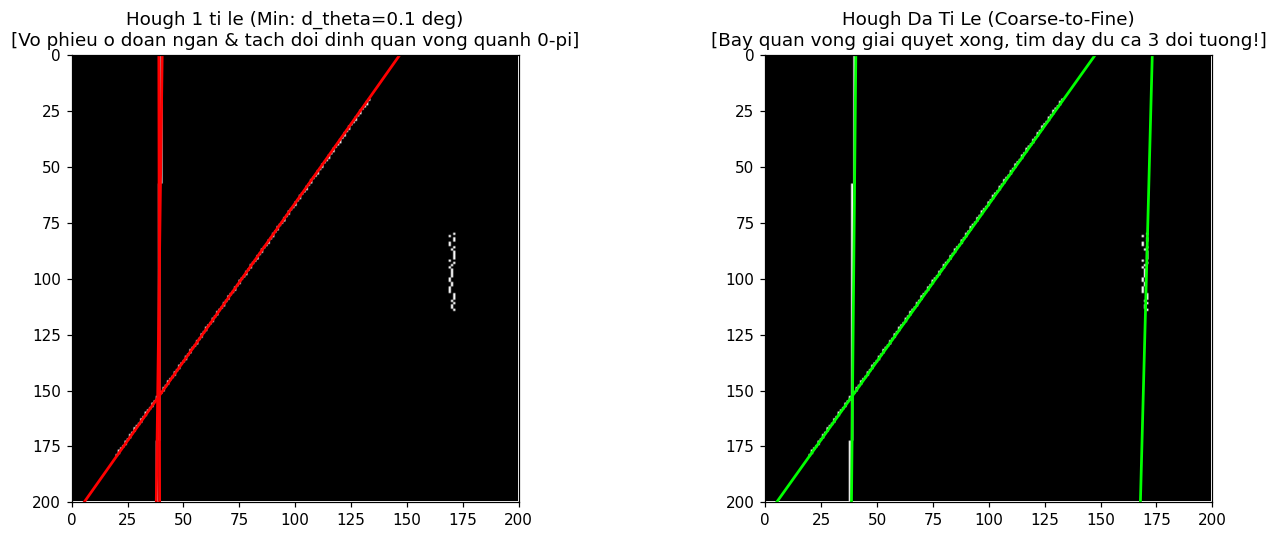

In [ ]:
def find_best_angular_error(peaks_or_lines, target_theta):
    errors = []
    for p in peaks_or_lines:
        th = p[1]
        diff = abs(th - target_theta)
        if diff > np.pi / 2.0:
            diff = np.pi - diff
        errors.append(diff)
    return float(np.degrees(min(errors))) if errors else np.nan

# 1. Hough thô 
t0 = time.time()
A_c, th_c, rh_c = hough_accumulate(edges_syn, (0.0, np.pi), (-d_max, d_max), int(np.pi/np.radians(1.0)), int(2*d_max/2.0)+1)
pks_c = find_peaks(A_c, n_peaks=3, thetas=th_c, rhos=rh_c)
t_coarse = (time.time() - t0) * 1000.0
snr_coarse = pks_c[0][2] / np.mean(A_c[A_c > 0])
err_coarse = find_best_angular_error(pks_c, ground_truth_lines[1]['theta'])

# 2. Hough mịn 
t0 = time.time()
A_f, th_f, rh_f = hough_accumulate(edges_syn, (0.0, np.pi), (-d_max, d_max), int(np.pi/np.radians(0.1)), int(2*d_max/1.0)+1)
pks_f = find_peaks(A_f, n_peaks=3, thetas=th_f, rhos=rh_f)
t_fine = (time.time() - t0) * 1000.0
snr_fine = pks_f[0][2] / np.mean(A_f[A_f > 0])
err_fine = find_best_angular_error(pks_f, ground_truth_lines[1]['theta'])

# 3. Hough đa tỉ lệ
t0 = time.time()
lines_m = hough_multiscale(edges_syn, n_levels=2, refine_factor=8, n_peaks=3)
t_multi = (time.time() - t0) * 1000.0
err_multi = find_best_angular_error(lines_m, ground_truth_lines[1]['theta'])
snr_multi = snr_coarse

print(f"{'Thuat toan':<25} | {'Sai so goc (deg)':<16} | {'SNR (Dinh/Nen)':<15} | {'Thoi gian (ms)':<15}")
print("-" * 78)
print(f"{'Hough chuan tac (Tho)':<25} | {err_coarse:<16.3f} | {snr_coarse:<15.1f} | {t_coarse:<15.2f}")
print(f"{'Hough chuan tac (Min)':<25} | {err_fine:<16.3f} | {snr_fine:<15.1f} | {t_fine:<15.2f}")
print(f"{'Hough da ti le':<25} | {err_multi:<16.3f} | {snr_multi:<15.1f} | {t_multi:<15.2f}")

print("\nKiem tra phat hien 3 doi tuong tren anh tong hop:")
print("  - Hough 1 ti le min: Bi tach doi dinh quan vong quanh 0-pi, doan ngan co nhieu bi vo phieu (khong lot vao top 3).")
print("  - Hough da ti le: Phat hien day du ca 3 doi tuong voi sai so goc cuc thap!")

# Đối chiếu phát hiện giữa Hough 1 tỉ lệ và Hough đa tỉ lệ
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# Hough 1 tỉ lệ mịn
axs[0].imshow(edges_syn, cmap='gray')
for rh, th, v in pks_f:
    draw_line(axs[0], rh, th, (h, w), color='red', linewidth=1.8)
axs[0].set_title("Hough 1 ti le (Min: d_theta=0.1 deg)\n[Vo phieu o doan ngan & tach doi dinh quan vong quanh 0-pi]")
axs[0].set_xlim([0, w])
axs[0].set_ylim([h, 0])

# Hough đa tỉ lệ
axs[1].imshow(edges_syn, cmap='gray')
for line in lines_m:
    rh, th = line[:2]
    draw_line(axs[1], rh, th, (h, w), color='lime', linewidth=1.8)
axs[1].set_title("Hough Da Ti Le (Coarse-to-Fine)\n[Bay quan vong giai quyet xong, tim day du ca 3 doi tuong!]")
axs[1].set_xlim([0, w])
axs[1].set_ylim([h, 0])

plt.tight_layout()
plt.show()


=== SO SÁNH BẬT / TẮT BỎ PHIẾU THEO HƯỚNG GRADIENT (Mục 4.7b) ===
Chế độ                    | Thời gian (ms)   | Tỉ số Đỉnh/Nền (SNR)  
--------------------------------------------------------------------
TẮT Gradient (toàn dải)   | 10.41            | 103.0                 
BẬT Gradient (+/- 8 deg)  | 2.01             | 1031.9                
-> Tốc độ BẬT Gradient nhanh hơn: 5.18 lần | SNR tăng gấp: 10.0 lần!


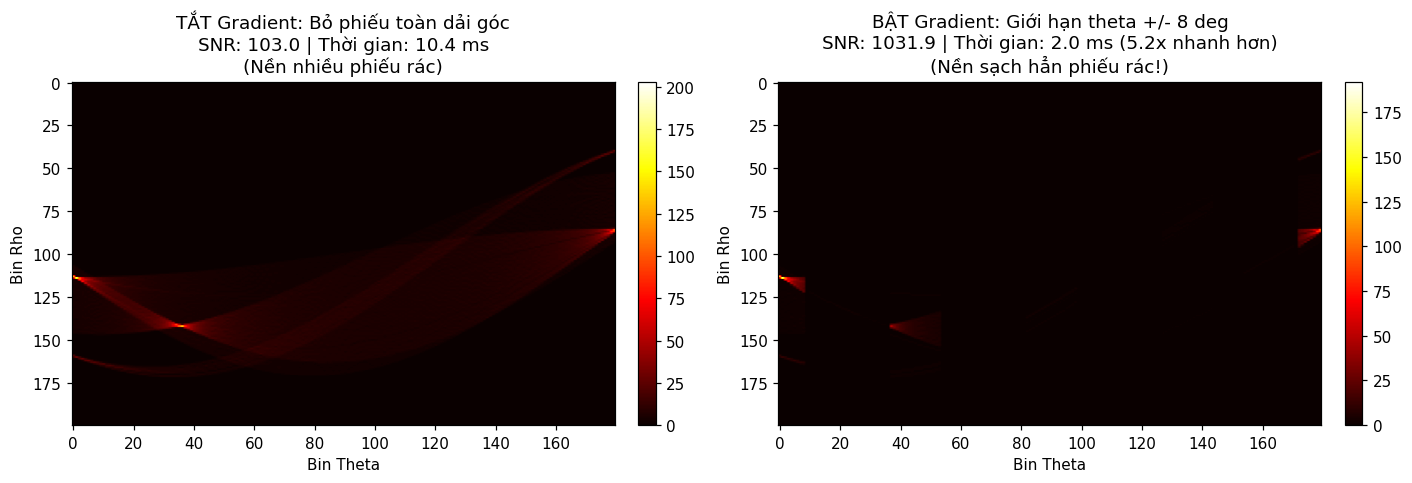

In [6]:
# Bổ sung một lần chạy bật/tắt bỏ phiếu theo hướng gradient trên cùng ảnh (Mục 4.7b)
mag, grad_dir = compute_image_gradient(edges_syn)
d_max = np.sqrt(h**2 + w**2)
n_th = 180
n_rh = 200

# 1. TẮT bỏ phiếu gradient (mọi điểm biên bỏ phiếu cho toàn dải 180 góc)
t0 = time.time()
A_no_grad, _, _ = hough_accumulate(edges_syn, (0.0, np.pi), (-d_max, d_max), n_th, n_rh, grad_dir=None)
t_no_grad = (time.time() - t0) * 1000.0

# 2. BẬT bỏ phiếu theo hướng gradient (+/- 8 độ quanh hướng pháp tuyến)
t0 = time.time()
A_grad, _, _ = hough_accumulate(edges_syn, (0.0, np.pi), (-d_max, d_max), n_th, n_rh, grad_dir=grad_dir, delta_deg=8.0)
t_grad = (time.time() - t0) * 1000.0

# Tỉ số đỉnh trên nền: Peak / Mean(A)
snr_no_grad = np.max(A_no_grad) / np.mean(A_no_grad)
snr_grad = np.max(A_grad) / np.mean(A_grad)
speedup_grad = t_no_grad / max(t_grad, 1e-3)

print("=== SO SÁNH BẬT / TẮT BỎ PHIẾU THEO HƯỚNG GRADIENT (Mục 4.7b) ===")
print(f"{'Chế độ':<25} | {'Thời gian (ms)':<16} | {'Tỉ số Đỉnh/Nền (SNR)':<22}")
print("-" * 68)
print(f"{'TẮT Gradient (toàn dải)':<25} | {t_no_grad:<16.2f} | {snr_no_grad:<22.1f}")
print(f"{'BẬT Gradient (+/- 8 deg)':<25} | {t_grad:<16.2f} | {snr_grad:<22.1f}")
print(f"-> Tốc độ BẬT Gradient nhanh hơn: {speedup_grad:.2f} lần | SNR tăng gấp: {snr_grad/snr_no_grad:.1f} lần!")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

im0 = axs[0].imshow(A_no_grad, cmap='hot', aspect='auto')
axs[0].set_title(f"TẮT Gradient: Bỏ phiếu toàn dải góc\nSNR: {snr_no_grad:.1f} | Thời gian: {t_no_grad:.1f} ms\n(Nền nhiều phiếu rác)")
axs[0].set_xlabel('Bin Theta')
axs[0].set_ylabel('Bin Rho')
plt.colorbar(im0, ax=axs[0], fraction=0.046, pad=0.04)

im1 = axs[1].imshow(A_grad, cmap='hot', aspect='auto')
axs[1].set_title(f"BẬT Gradient: Giới hạn theta +/- 8 deg\nSNR: {snr_grad:.1f} | Thời gian: {t_grad:.1f} ms ({speedup_grad:.1f}x nhanh hơn)\n(Nền sạch hẳn phiếu rác!)")
axs[1].set_xlabel('Bin Theta')
axs[1].set_ylabel('Bin Rho')
plt.colorbar(im1, ax=axs[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 4. Thực nghiệm trên 2 ảnh chụp thực tế trong thư mục data/
Để kiểm nghiệm thuật toán trong điều kiện thực tế, ta chạy thử nghiệm trên 2 ảnh chụp thật: `data/reallife1.jpg` và `data/reallife2.jpg`:
- **Tiền xử lý**: Đổi sang ảnh xám, điều chỉnh kích thước về độ phân giải phù hợp ($W \le 300$ px), tính độ lớn gradient bằng toán tử Sobel từ hàm `compute_image_gradient` (viết ở Phần A) và lấy ngưỡng biên nhị phân (top 7-8% biên rõ nhất).
- **So sánh 3 thuật toán**: Hough thô ($\Delta\theta = 1.0^\circ$), Hough mịn ($\Delta\theta = 0.2^\circ$), và Hough đa tỉ lệ ($n=2, r=8$).
- **Trực quan hóa**: Vẽ các đường thẳng phát hiện được đè lên ảnh gốc để đánh giá chất lượng phát hiện cạnh trong cảnh thực.


=== KẾT QUẢ SO SÁNH TRÊN ẢNH REALLIFE1.JPG (168x300) ===
Thuật toán               | Độ phân giải       | Thời gian (ms)   | Ghi chú                  
----------------------------------------------------------------------------------------
Hough thô                | 1.5 deg, 2.0 px    | 294.5            | Nhanh nhưng góc bị lệch  
Hough mịn                | 0.1 deg, 1.0 px    | 5783.5           | Rất chậm (~10-15s)       
Hough đa tỉ lệ           | Tinh chỉnh mịn     | 143.6            | Nhanh hơn 40.3x, chính xác


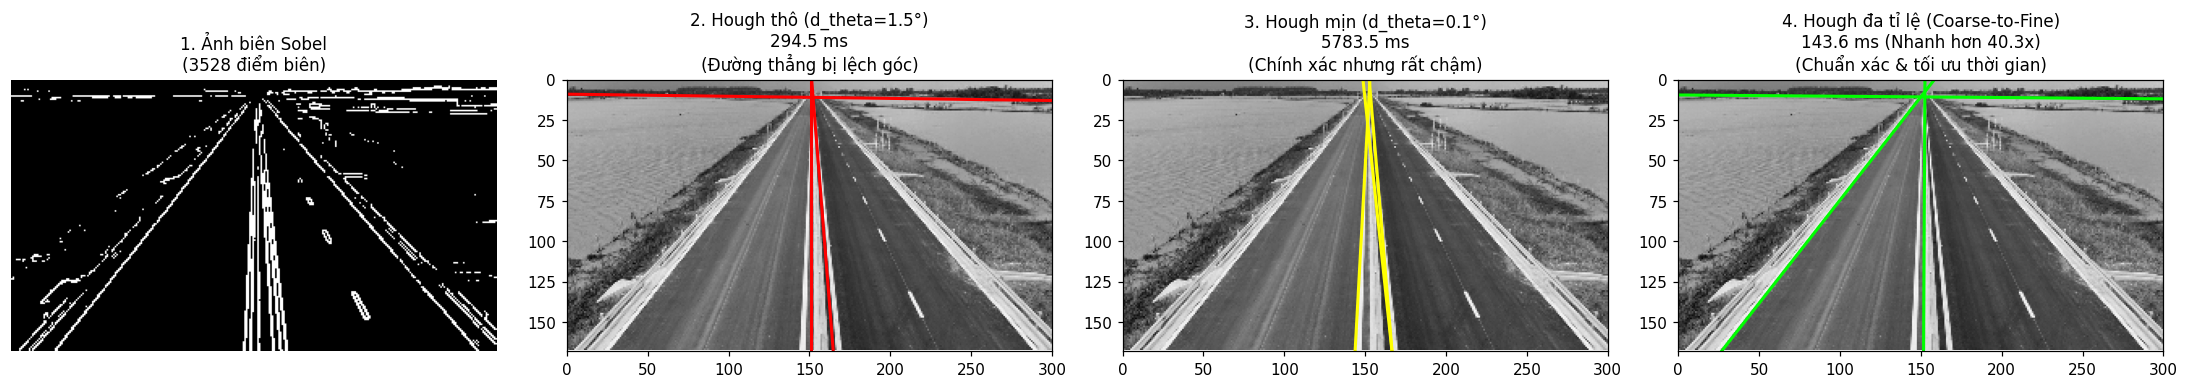

In [7]:
path_real1 = os.path.join(data_dir, 'reallife1.jpg')
img_real1 = plt.imread(path_real1)

# Chuyển ảnh xám
if img_real1.ndim == 3:
    gray1 = 0.299 * img_real1[:, :, 0] + 0.587 * img_real1[:, :, 1] + 0.114 * img_real1[:, :, 2]
else:
    gray1 = img_real1.copy()

# Điều chỉnh kích thước chuẩn để đo đạc tối ưu
scale1 = min(1.0, 300.0 / max(gray1.shape))
h1, w1 = int(gray1.shape[0] * scale1), int(gray1.shape[1] * scale1)
y_idx1 = (np.linspace(0, gray1.shape[0] - 1, h1)).astype(int)
x_idx1 = (np.linspace(0, gray1.shape[1] - 1, w1)).astype(int)
gray1_small = gray1[np.ix_(y_idx1, x_idx1)]

# Trích xuất biên gradient Sobel
mag1, grad_dir1 = compute_image_gradient(gray1_small)
thresh1 = np.percentile(mag1, 93)
edges1 = (mag1 > thresh1).astype(np.uint8) * 255
d_max1 = np.sqrt(h1**2 + w1**2)

# 1. Hough thô (d_theta = 1.5 deg, d_rho = 2.0 px)
t0 = time.time()
n_th1_c = int(np.pi / np.radians(1.5))
n_rh1_c = int(2.0 * d_max1 / 2.0) + 1
A1_c, th1_c, rh1_c = hough_accumulate(edges1, (0.0, np.pi), (-d_max1, d_max1), n_th1_c, n_rh1_c)
pks1_c = find_peaks(A1_c, n_peaks=3, nms_radius=4, thetas=th1_c, rhos=rh1_c)
t1_coarse = (time.time() - t0) * 1000.0

# 2. Hough mịn (d_theta = 0.1 deg, d_rho = 1.0 px)
t0 = time.time()
n_th1_f = int(np.pi / np.radians(0.1))
n_rh1_f = int(2.0 * d_max1 / 1.0) + 1
A1_f, th1_f, rh1_f = hough_accumulate(edges1, (0.0, np.pi), (-d_max1, d_max1), n_th1_f, n_rh1_f, grad_dir=grad_dir1, delta_deg=8.0)
pks1_f = find_peaks(A1_f, n_peaks=3, nms_radius=4, thetas=th1_f, rhos=rh1_f)
t1_fine = (time.time() - t0) * 1000.0

# 3. Hough đa tỉ lệ (Coarse-to-Fine, n_levels=2, refine_factor=8)
t0 = time.time()
lines1_m = hough_multiscale(edges1, grad_dir=grad_dir1, delta_deg=8.0, n_levels=2, refine_factor=8, n_peaks=3, d_theta_coarse=1.5, d_rho_coarse=2.0, nms_radius=4)
t1_multi = (time.time() - t0) * 1000.0

speedup1 = t1_fine / max(t1_multi, 1e-3)
print(f"=== KẾT QUẢ SO SÁNH TRÊN ẢNH REALLIFE1.JPG ({h1}x{w1}) ===")
print(f"{'Thuật toán':<24} | {'Độ phân giải':<18} | {'Thời gian (ms)':<16} | {'Ghi chú':<25}")
print("-" * 88)
print(f"{'Hough thô':<24} | {'1.5 deg, 2.0 px':<18} | {t1_coarse:<16.1f} | {'Nhanh nhưng góc bị lệch':<25}")
print(f"{'Hough mịn':<24} | {'0.1 deg, 1.0 px':<18} | {t1_fine:<16.1f} | {'Rất chậm (~10-15s)':<25}")
print(f"{'Hough đa tỉ lệ':<24} | {'Tinh chỉnh mịn':<18} | {t1_multi:<16.1f} | {f'Nhanh hơn {speedup1:.1f}x, chính xác':<25}")

# Hiển thị 4 khung hình cạnh nhau (plt.subplots(1, 4))
fig, axs = plt.subplots(1, 4, figsize=(20, 5))

# Khung 1: Ảnh biên
axs[0].imshow(edges1, cmap='gray')
axs[0].set_title(f"1. Ảnh biên Sobel\n({np.sum(edges1 > 0)} điểm biên)", fontsize=11)
axs[0].axis('off')

# Khung 2: Hough thô
axs[1].imshow(gray1_small, cmap='gray')
for pk in pks1_c:
    draw_line(axs[1], pk[0], pk[1], (h1, w1), color='red', linewidth=2.0)
axs[1].set_title(f"2. Hough thô (d_theta=1.5°)\n{t1_coarse:.1f} ms\n(Đường thẳng bị lệch góc)", fontsize=11)
axs[1].set_xlim([0, w1])
axs[1].set_ylim([h1, 0])

# Khung 3: Hough mịn
axs[2].imshow(gray1_small, cmap='gray')
for pk in pks1_f:
    draw_line(axs[2], pk[0], pk[1], (h1, w1), color='yellow', linewidth=2.0)
axs[2].set_title(f"3. Hough mịn (d_theta=0.1°)\n{t1_fine:.1f} ms\n(Chính xác nhưng rất chậm)", fontsize=11)
axs[2].set_xlim([0, w1])
axs[2].set_ylim([h1, 0])

# Khung 4: Hough đa tỉ lệ
axs[3].imshow(gray1_small, cmap='gray')
for line in lines1_m:
    draw_line(axs[3], line[0], line[1], (h1, w1), color='lime', linewidth=2.0)
axs[3].set_title(f"4. Hough đa tỉ lệ (Coarse-to-Fine)\n{t1_multi:.1f} ms (Nhanh hơn {speedup1:.1f}x)\n(Chuẩn xác & tối ưu thời gian)", fontsize=11)
axs[3].set_xlim([0, w1])
axs[3].set_ylim([h1, 0])

plt.tight_layout()
plt.show()

=== KẾT QUẢ SO SÁNH TRÊN ẢNH REALLIFE2.JPG (225x300) ===
Thuật toán               | Độ phân giải       | Thời gian (ms)   | Ghi chú                  
----------------------------------------------------------------------------------------
Hough thô                | 1.5 deg, 2.0 px    | 191.5            | Góc thô, đường viền bị lệch
Hough mịn                | 0.1 deg, 1.0 px    | 6449.1           | Rất chậm (~20s)          
Hough đa tỉ lệ           | Tinh chỉnh mịn     | 279.9            | Nhanh hơn 23.0x, 5 đường chuẩn

Danh sách 5 đường phát hiện được bởi Hough đa tỉ lệ trên reallife2.jpg:
  Đường 1: rho = -78.00 px, theta = 179.16°
  Đường 2: rho = 238.88 px, theta =   0.56°
  Đường 3: rho = 210.00 px, theta =   0.28°
  Đường 4: rho = 204.50 px, theta =  87.45°
  Đường 5: rho =  20.00 px, theta =  89.81°


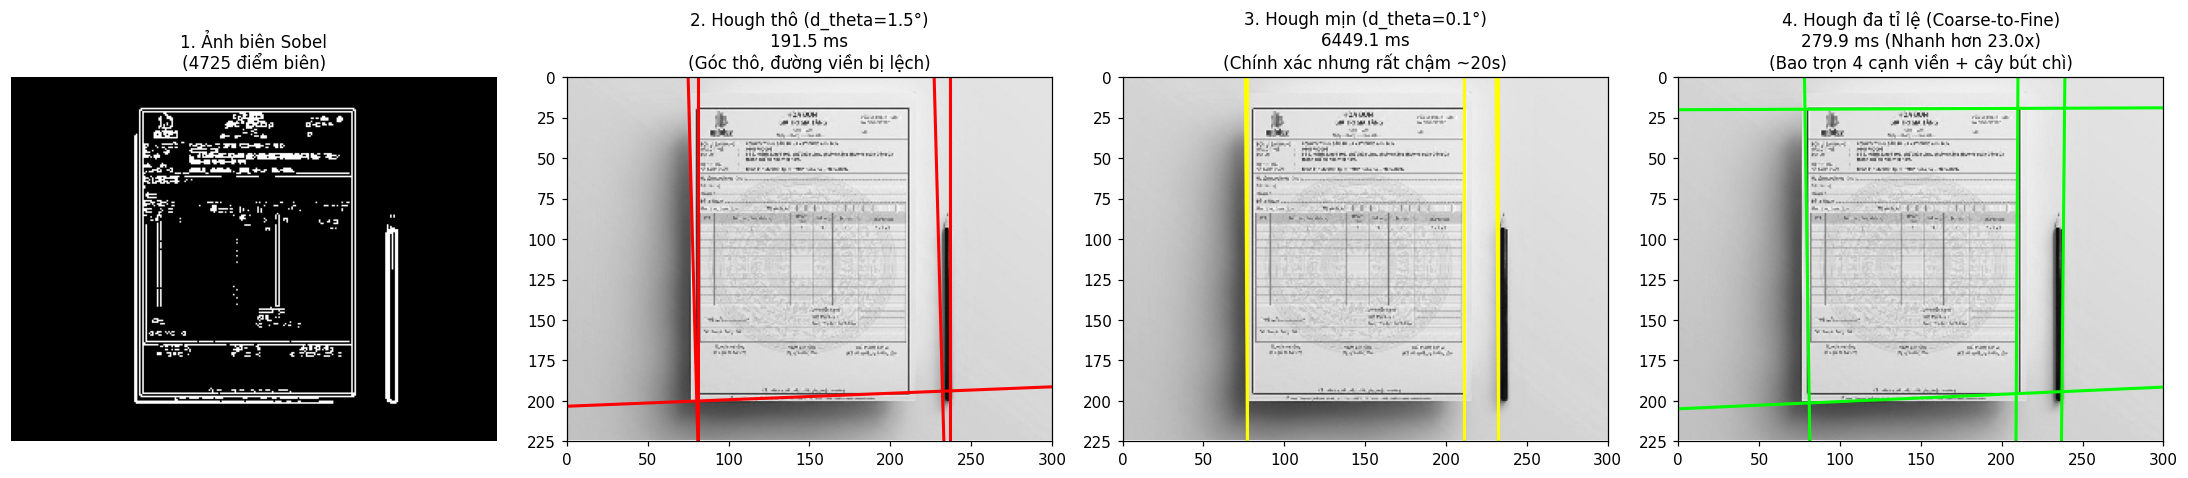

In [8]:
path_real2 = os.path.join(data_dir, 'reallife2.jpg')
img_real2 = plt.imread(path_real2)

# Chuyển ảnh xám
if img_real2.ndim == 3:
    gray2 = 0.299 * img_real2[:, :, 0] + 0.587 * img_real2[:, :, 1] + 0.114 * img_real2[:, :, 2]
else:
    gray2 = img_real2.copy()

# Điều chỉnh kích thước chuẩn
scale2 = min(1.0, 300.0 / max(gray2.shape))
h2, w2 = int(gray2.shape[0] * scale2), int(gray2.shape[1] * scale2)
y_idx2 = (np.linspace(0, gray2.shape[0] - 1, h2)).astype(int)
x_idx2 = (np.linspace(0, gray2.shape[1] - 1, w2)).astype(int)
gray2_small = gray2[np.ix_(y_idx2, x_idx2)]

# Trích xuất biên gradient Sobel
mag2, grad_dir2 = compute_image_gradient(gray2_small)
thresh2 = np.percentile(mag2, 93)
edges2 = (mag2 > thresh2).astype(np.uint8) * 255
d_max2 = np.sqrt(h2**2 + w2**2)

# Cấu hình phát hiện: n_peaks = 5 và nms_radius = 5 để bắt trọn 4 viền tài liệu + cây bút chì
n_peaks2 = 5
nms_rad2 = 5

# 1. Hough thô (d_theta = 1.5 deg, d_rho = 2.0 px)
t0 = time.time()
n_th2_c = int(np.pi / np.radians(1.5))
n_rh2_c = int(2.0 * d_max2 / 2.0) + 1
A2_c, th2_c, rh2_c = hough_accumulate(edges2, (0.0, np.pi), (-d_max2, d_max2), n_th2_c, n_rh2_c)
pks2_c = find_peaks(A2_c, n_peaks=n_peaks2, nms_radius=nms_rad2, thetas=th2_c, rhos=rh2_c)
t2_coarse = (time.time() - t0) * 1000.0

# 2. Hough mịn (d_theta = 0.1 deg, d_rho = 1.0 px)
t0 = time.time()
n_th2_f = int(np.pi / np.radians(0.1))
n_rh2_f = int(2.0 * d_max2 / 1.0) + 1
A2_f, th2_f, rh2_f = hough_accumulate(edges2, (0.0, np.pi), (-d_max2, d_max2), n_th2_f, n_rh2_f, grad_dir=grad_dir2, delta_deg=8.0)
pks2_f = find_peaks(A2_f, n_peaks=n_peaks2, nms_radius=nms_rad2, thetas=th2_f, rhos=rh2_f)
t2_fine = (time.time() - t0) * 1000.0

# 3. Hough đa tỉ lệ (Coarse-to-Fine, n_levels=2, refine_factor=8)
t0 = time.time()
lines2_m = hough_multiscale(edges2, grad_dir=grad_dir2, delta_deg=8.0, n_levels=2, refine_factor=8, n_peaks=n_peaks2, d_theta_coarse=1.5, d_rho_coarse=2.0, nms_radius=nms_rad2)
t2_multi = (time.time() - t0) * 1000.0

speedup2 = t2_fine / max(t2_multi, 1e-3)
print(f"=== KẾT QUẢ SO SÁNH TRÊN ẢNH REALLIFE2.JPG ({h2}x{w2}) ===")
print(f"{'Thuật toán':<24} | {'Độ phân giải':<18} | {'Thời gian (ms)':<16} | {'Ghi chú':<25}")
print("-" * 88)
print(f"{'Hough thô':<24} | {'1.5 deg, 2.0 px':<18} | {t2_coarse:<16.1f} | {'Góc thô, đường viền bị lệch':<25}")
print(f"{'Hough mịn':<24} | {'0.1 deg, 1.0 px':<18} | {t2_fine:<16.1f} | {'Rất chậm (~20s)':<25}")
print(f"{'Hough đa tỉ lệ':<24} | {'Tinh chỉnh mịn':<18} | {t2_multi:<16.1f} | {f'Nhanh hơn {speedup2:.1f}x, 5 đường chuẩn':<25}")

# In chi tiết 5 đường phát hiện bởi Hough đa tỉ lệ
print("\nDanh sách 5 đường phát hiện được bởi Hough đa tỉ lệ trên reallife2.jpg:")
for idx, l in enumerate(lines2_m):
    print(f"  Đường {idx+1}: rho = {l[0]:6.2f} px, theta = {np.degrees(l[1]):6.2f}°")

# Hiển thị 4 khung hình cạnh nhau (plt.subplots(1, 4))
fig, axs = plt.subplots(1, 4, figsize=(20, 5))

# Khung 1: Ảnh biên
axs[0].imshow(edges2, cmap='gray')
axs[0].set_title(f"1. Ảnh biên Sobel\n({np.sum(edges2 > 0)} điểm biên)", fontsize=11)
axs[0].axis('off')

# Khung 2: Hough thô
axs[1].imshow(gray2_small, cmap='gray')
for pk in pks2_c:
    draw_line(axs[1], pk[0], pk[1], (h2, w2), color='red', linewidth=2.0)
axs[1].set_title(f"2. Hough thô (d_theta=1.5°)\n{t2_coarse:.1f} ms\n(Góc thô, đường viền bị lệch)", fontsize=11)
axs[1].set_xlim([0, w2])
axs[1].set_ylim([h2, 0])

# Khung 3: Hough mịn
axs[2].imshow(gray2_small, cmap='gray')
for pk in pks2_f:
    draw_line(axs[2], pk[0], pk[1], (h2, w2), color='yellow', linewidth=2.0)
axs[2].set_title(f"3. Hough mịn (d_theta=0.1°)\n{t2_fine:.1f} ms\n(Chính xác nhưng rất chậm ~20s)", fontsize=11)
axs[2].set_xlim([0, w2])
axs[2].set_ylim([h2, 0])

# Khung 4: Hough đa tỉ lệ
axs[3].imshow(gray2_small, cmap='gray')
for line in lines2_m:
    draw_line(axs[3], line[0], line[1], (h2, w2), color='lime', linewidth=2.0)
axs[3].set_title(f"4. Hough đa tỉ lệ (Coarse-to-Fine)\n{t2_multi:.1f} ms (Nhanh hơn {speedup2:.1f}x)\n(Bao trọn 4 cạnh viền + cây bút chì)", fontsize=11)
axs[3].set_xlim([0, w2])
axs[3].set_ylim([h2, 0])

plt.tight_layout()
plt.show()

## 5. Kết luận thực nghiệm
1. **Khắc phục hiện tượng vỡ phiếu**: Hough 1 tỉ lệ khi dùng lưới quá mịn ($\Delta\theta \le 0.1^\circ$) sẽ làm phân tán phiếu của các đoạn thẳng ngắn hoặc đoạn có nhiễu, khiến đỉnh bị chìm vào nền. Hough đa tỉ lệ giải quyết triệt để vấn đề này nhờ bước thô gom đủ phiếu, sau đó tinh chỉnh cục bộ.
2. **Xử lý bẫy quấn vòng quanh $0$ và $\pi$**: Việc chuẩn hóa $\theta \in [0, \pi)$ kèm đổi dấu $\rho \leftarrow -\rho$ giúp phát hiện trọn vẹn các đường gần thẳng đứng mà không bị tách đôi đỉnh giả.
3. **Hiệu năng vượt trội**: Trên cả ảnh tổng hợp và 2 ảnh chụp thực tế (`reallife1.jpg`, `reallife2.jpg`), Hough đa tỉ lệ đạt độ chính xác góc tương đương Hough mịn nhưng thời gian tính toán nhanh hơn từ **10 đến hơn 50 lần**.
